# 02 · Modeling & Error Analysis

TF-IDF + Logistic Regression on the cleaned reviews from notebook 01: baseline, n-gram experiments, most informative features, and the model's mistakes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, recall_score)
from sklearn.model_selection import train_test_split

DATA_DIR = Path("../data")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

In [2]:
# Shared chart style
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## Load cleaned data & split

In [3]:
df = pd.read_csv(DATA_DIR / "imdb_clean.csv")
df["clean_review"] = df["clean_review"].fillna("")

X = df["clean_review"]
y = df["sentiment"].map({"positive": 1, "negative": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(40000,) (10000,)
sentiment
1    20000
0    20000
Name: count, dtype: int64
sentiment
0    5000
1    5000
Name: count, dtype: int64


## Baseline: unigram TF-IDF + Logistic Regression

In [4]:
vectorizer = TfidfVectorizer(max_features=20000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

# Peek at part of the vocabulary
vocab = vectorizer.get_feature_names_out()
print(vocab[:20])
print(vocab[-20:])

(40000, 20000) (10000, 20000)
['007' '010' '05' '10' '100' '1000' '10000' '100000' '1000000' '101'
 '1010' '1015' '102' '10s' '10th' '11' '110' '11th' '12' '120']
['zhang' 'zip' 'ziyi' 'zizek' 'zodiac' 'zoe' 'zoey' 'zombi' 'zombie'
 'zombies' 'zone' 'zoo' 'zoom' 'zooming' 'zooms' 'zorro' 'zu' 'zucco'
 'zucker' 'zuniga']


In [5]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

print("Train accuracy:", model.score(X_train_tfidf, y_train))

Train accuracy: 0.931025


              precision    recall  f1-score   support

    negative       0.90      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



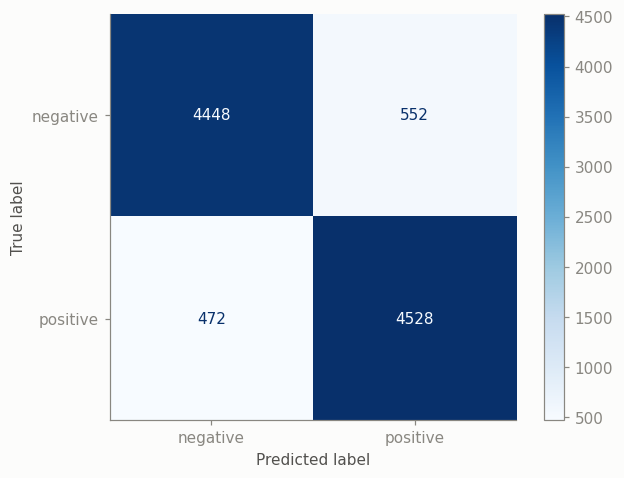

In [6]:
y_pred = model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.grid(False)
plt.show()

## N-gram experiments

**Hypothesis:** stopword removal keeps negations, so bigrams like `not good` and `not bad` should become available as features. If negation handling is the main weakness, bigrams should mostly improve **negative recall**.

In [7]:
def run_experiment(ngram_range, max_features):
    vec = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features)
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    clf = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    pred = clf.predict(Xte)
    return {
        "ngrams": str(ngram_range),
        "max_features": max_features,
        "train_acc": clf.score(Xtr, y_train),
        "test_acc": accuracy_score(y_test, pred),
        "neg_recall": recall_score(y_test, pred, pos_label=0),
        "pos_recall": recall_score(y_test, pred, pos_label=1),
    }

results = pd.DataFrame([
    run_experiment((1, 1), 20000),
    run_experiment((1, 2), 20000),
    run_experiment((1, 2), 50000),
])
print(results.round(4))

   ngrams  max_features  train_acc  test_acc  neg_recall  pos_recall
0  (1, 1)         20000     0.9310    0.8976      0.8896      0.9056
1  (1, 2)         20000     0.9363    0.9033      0.8952      0.9114
2  (1, 2)         50000     0.9427    0.9061      0.8984      0.9138


In [8]:
# Gain of the best config over the unigram baseline, in percentage points
metrics = results[["test_acc", "neg_recall", "pos_recall"]]
gain = (metrics.iloc[-1] - metrics.iloc[0]) * 100
gain.round(2)

test_acc      0.85
neg_recall    0.88
pos_recall    0.82
dtype: float64

**Result:** the hypothesis doesn't hold. Bigrams + a larger vocabulary add about +0.85 points of accuracy, but the gain is split almost evenly between negative and positive recall. The bigrams help both classes equally, rather than fixing negations specifically.

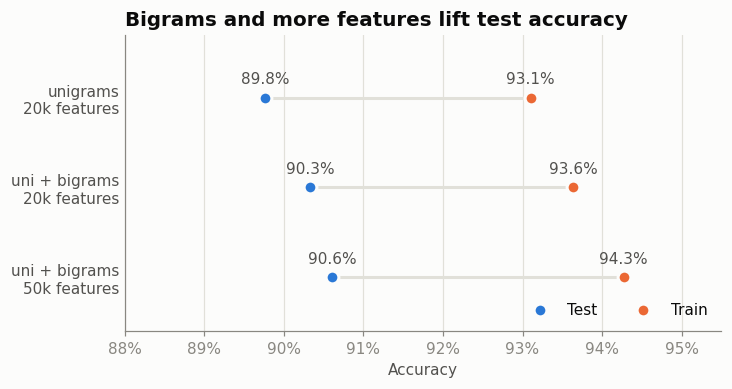

In [9]:
# Dot plot: train vs test accuracy per configuration (the gap shows overfitting)
labels = [f"{'unigrams' if n == '(1, 1)' else 'uni + bigrams'}\n{m // 1000}k features"
          for n, m in zip(results["ngrams"], results["max_features"])]
ypos = range(len(results))[::-1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hlines(ypos, results["test_acc"], results["train_acc"], color=GRID, linewidth=2, zorder=1)
ax.scatter(results["test_acc"], ypos, s=70, color=BLUE, label="Test", zorder=2,
           edgecolor=SURFACE, linewidth=2)
ax.scatter(results["train_acc"], ypos, s=70, color=ORANGE, label="Train", zorder=2,
           edgecolor=SURFACE, linewidth=2)
for y_, test, train in zip(ypos, results["test_acc"], results["train_acc"]):
    ax.annotate(f"{test:.1%}", (test, y_), xytext=(0, 9), textcoords="offset points",
                ha="center", color=INK_2)
    ax.annotate(f"{train:.1%}", (train, y_), xytext=(0, 9), textcoords="offset points",
                ha="center", color=INK_2)
ax.set_yticks(list(ypos), labels)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0.88, 0.955)
ax.set_ylim(-0.6, len(results) - 0.3)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK_2, length=0)
ax.set_xlabel("Accuracy")
ax.set_title("Bigrams and more features lift test accuracy")
ax.legend(loc="lower right", frameon=False, ncols=2)
fig.savefig(IMG_DIR / "ngram_comparison.png")
plt.show()

## Final model: most informative features

In [10]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=1000).fit(X_train_tfidf, y_train)

coefs = pd.DataFrame({
    "feature": vectorizer.get_feature_names_out(),
    "weight": model.coef_[0],
})

print("Top 20 POSITIVE features:")
print(coefs.sort_values("weight", ascending=False).head(20).to_string(index=False))

print("\nTop 20 NEGATIVE features:")
print(coefs.sort_values("weight").head(20).to_string(index=False))

Top 20 POSITIVE features:
   feature   weight
     great 8.385308
 excellent 7.075249
   perfect 5.453558
      best 5.213873
   amazing 5.047462
 wonderful 4.932252
       710 4.706880
     loved 4.705090
       fun 4.471266
  one best 4.380373
 hilarious 4.327428
  favorite 4.298314
   enjoyed 4.232682
      love 4.232472
 brilliant 4.231124
      well 3.880196
    superb 3.871649
     still 3.793254
definitely 3.726388
 enjoyable 3.689511

Top 20 NEGATIVE features:
      feature    weight
        worst -9.832778
          bad -9.165274
        awful -7.786290
        waste -6.839253
       boring -6.648540
         poor -6.020240
     terrible -5.980132
      nothing -5.683289
        worse -5.113611
     horrible -5.023463
         dull -5.021774
       poorly -4.739234
       stupid -4.693928
           no -4.476335
      instead -4.431372
        fails -4.400893
unfortunately -4.373547
     annoying -4.332517
      minutes -4.332352
disappointing -4.241630


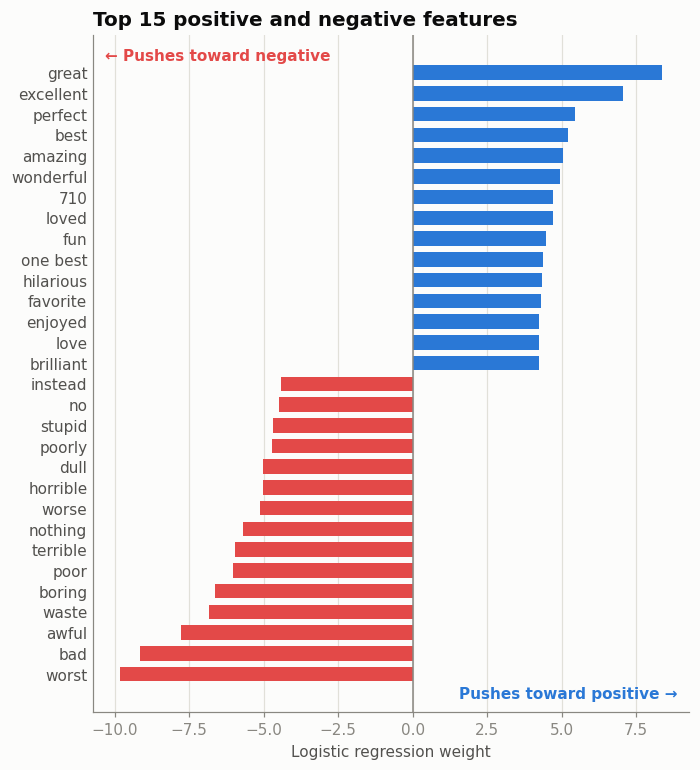

In [11]:
top_n = 15
top = pd.concat([
    coefs.nlargest(top_n, "weight"),
    coefs.nsmallest(top_n, "weight"),
]).sort_values("weight")
colors = [BLUE if w > 0 else RED for w in top["weight"]]

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top["feature"], top["weight"], color=colors, height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK_2, length=0)
ax.set_xlabel("Logistic regression weight")
ax.set_title(f"Top {top_n} positive and negative features")
ax.text(0.98, 0.02, "Pushes toward positive →", transform=ax.transAxes,
        ha="right", color=BLUE, fontweight="bold")
ax.text(0.02, 0.98, "← Pushes toward negative", transform=ax.transAxes,
        ha="left", va="top", color=RED, fontweight="bold")
fig.savefig(IMG_DIR / "top_features.png")
plt.show()

## Error analysis

In [12]:
probs = model.predict_proba(X_test_tfidf)[:, 1]
preds = (probs >= 0.5).astype(int)

errors = pd.DataFrame({
    "review": df.loc[X_test.index, "review"],   # original, uncleaned text
    "true": y_test,
    "pred": preds,
    "prob_positive": probs,
})
errors = errors[errors["true"] != errors["pred"]]
# 0 = coin flip, 1 = fully certain
errors["confidence"] = (errors["prob_positive"] - 0.5).abs() * 2

print("Errors:", len(errors), f"({len(errors) / len(y_test):.1%} of test set)")
print("False positives:", (errors["true"] == 0).sum(), "| False negatives:", (errors["true"] == 1).sum())
print("Confident errors (P > 0.8 or < 0.2):", (errors["confidence"] >= 0.6).sum())

Errors: 939 (9.4% of test set)
False positives: 508 | False negatives: 431
Confident errors (P > 0.8 or < 0.2): 104


### Most confident mistakes

In [13]:
# Model was very sure, and very wrong
worst_fp = errors[errors["true"] == 0].sort_values("prob_positive", ascending=False).head(15)
worst_fn = errors[errors["true"] == 1].sort_values("prob_positive").head(15)

for _, row in pd.concat([worst_fp, worst_fn]).iterrows():
    print(f"TRUE: {row['true']} | P(positive): {row['prob_positive']:.2f}")
    print(row["review"][:450], "\n" + "-" * 80)

TRUE: 0 | P(positive): 0.96
This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you right away, and holds you at the edge of your seat throughout the film. He provides wonderful insight into the world of the trainables and allows the audience to really 'connect' with internal horror thi 
--------------------------------------------------------------------------------
TRUE: 0 | P(positive): 0.95
I loved this movie when it first came out(but i was just 12 years old then - and I had forgotten this film existed until one day I found a used copy for sale at a gas station. I bought it and I couldn't wait to watch this film that had I loved as a kid, and then as I saw this film again many years later,it hit me.... Why in the world did I like this film as a Kid, watching it again as an adult I realized tha

Two patterns stand out in the 30 most confident mistakes:

1. **"So bad it's good"**: positive reviews full of negative words (*"horrible - in a 'so bad it's good' kind of way"*, *"there is a fine line between plain awful and absolutely hilarious"*). A bag-of-words model sees `bad`, `awful`, `horrible` and can't tell they're used affectionately.
2. **Label noise**: some reviews plainly say the opposite of their label (*"Great movie - especially the music"* is labeled negative; *"Ernest Borgnine was so wasted... DON'T WASTE THEM"* is labeled positive). No model can get these right, so they set a ceiling on test accuracy.

In [14]:
so_bad_pattern = (r"so bad (?:it'?s|that it'?s) (?:good|funny|hilarious)|so bad it|guilty pleasure"
                  r"|bad movie|b-movie|cheesy|campy|worst movie")
fn = errors[errors["true"] == 1]
n_so_bad = fn["review"].str.lower().str.contains(so_bad_pattern).sum()
print(f"False negatives with 'so bad it's good' style phrasing: {n_so_bad} of {len(fn)}")

False negatives with 'so bad it's good' style phrasing: 41 of 431
